In [57]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [58]:
load_dotenv()

True

In [59]:
#define State 
class BatsmanState(TypedDict):
    runs: int
    balls: int 
    fours: int
    sixes: int

    strick_rate: float
    balls_per_boundry: float 
    boundry_perc: float 
    smry: str

In [60]:
def cal_strick_rate(state: BatsmanState):
    strick_rate = (state['runs']/state['balls'])*100

    return {'strick_rate': strick_rate}

In [61]:
def cal_balls_per_boundry(state: BatsmanState):
    balls_per_boundry = state['balls']/(state['fours']+state['sixes'])

    return {'balls_per_boundry': balls_per_boundry}

In [62]:
def cal_boundry_perc(state: BatsmanState):

    boundry_perc = (((state['fours'] * 4) + (state['sixes'] * 6))/state['runs'])*100

    
    return {'boundry_perc': boundry_perc}


In [63]:
def smry(state: BatsmanState):

    smry = f""""
    Strick Rate - {state['strick_rate']} \n
    Balls Per Boundary - {state['balls_per_boundry']}\n
    Boundary Percent - {state['boundry_perc']}
    """
    return {'smry': smry}

In [64]:
#define graph
graph = StateGraph(BatsmanState)

# Add Nodes
graph.add_node('cal_strick_rate', cal_strick_rate)
graph.add_node('cal_balls_per_boundry', cal_balls_per_boundry)
graph.add_node('cal_boundry_perc', cal_boundry_perc)
graph.add_node('smry', smry)

# Add Edges 
graph.add_edge(START, 'cal_strick_rate')
graph.add_edge(START, 'cal_balls_per_boundry')
graph.add_edge(START, 'cal_boundry_perc')

graph.add_edge('cal_strick_rate', 'smry')
graph.add_edge('cal_balls_per_boundry', 'smry')
graph.add_edge('cal_boundry_perc', 'smry')

graph.add_edge('smry', END)

workflow = graph.compile()

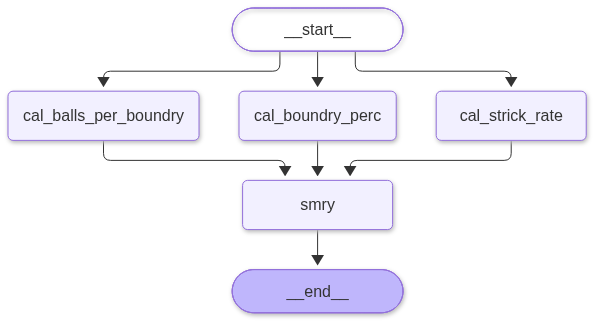

In [65]:
workflow

In [70]:
intial_state = {
    'runs': 80, 
    'balls': 55,
    'fours': 4,
    'sixes': 2
}

final_state = workflow.invoke(intial_state)

print(final_state['smry'])

"
    Strick Rate - 145.45454545454547 

    Balls Per Boundary - 9.166666666666666

    Boundary Percent - 35.0
    
